# 统计 ― stats 模块

## 本章要学什么

处理数据的波动时，除了平均值和方差，有时还要考虑分布的形状。`stats` 模块里放着表示各种概率分布的对象，这里的「随机变量」是概率论的术语，与 Python 的变量不是一回事；连续分布是 `rv_continuous` 的派生类，离散分布是 `rv_discrete` 的派生类。

- 随机变量的方法(`pdf`、`cdf`、`rvs`、`fit`)
- 用随机数与直方图确认分布的公式
- 自己定义离散分布
- 中心极限定理与核密度估计
- 二项分布、泊松分布、伽马分布
- t 检验与卡方检验

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import helper.matplotlib
import helper.magics
from scipy import stats

## 连续概率分布

`stats` 模块里的连续分布对象可以像下面这样列出来。

In [2]:
from scipy import stats

%col 4 [k for k, v in stats.__dict__.items() if isinstance(v, stats.rv_continuous)]

['ksone',                 'kstwo',                 'kstwobign',             'norm',                 
 'alpha',                 'anglit',                'arcsine',               'beta',                 
 'betaprime',             'bradford',              'burr',                  'burr12',               
 'fisk',                  'cauchy',                'chi',                   'chi2',                 
 'cosine',                'dgamma',                'dpareto_lognorm',       'dweibull',             
 'expon',                 'exponnorm',             'exponweib',             'exponpow',             
 'fatiguelife',           'foldcauchy',            'f',                     'foldnorm',             
 'weibull_min',           'truncweibull_min',      'weibull_max',           'genlogistic',          
 'genpareto',             'genexpon',              'genextreme',            'gamma',                
 'erlang',                'gengamma',              'genhalflogistic',       'genhyperbolic'

随机变量对象有这些方法。

* `rvs`：返回随机数，用 `size` 指定个数。
* `pdf`：概率密度函数。
* `cdf`：累积分布函数，也就是概率密度函数的积分。
* `sf`：生存函数，取值为 `1 - cdf(t)`。
* `ppf`：累积分布函数的反函数。
* `stats`：返回期望与方差。
* `fit`：估计与样本相合的分布参数。

下面以正态分布为例试一下，不带参数调用时就是平均值 0、方差 1 的标准正态分布。

In [3]:
stats.norm.stats()

(np.float64(0.0), np.float64(1.0))

`norm` 可以像函数一样调用，其中 `loc` 是位置(平均)、`scale` 是尺度(标准差)：标准差为 2 时，方差就是 4。

In [4]:
X = stats.norm(loc=1.0, scale=2.0)
X.stats()

(np.float64(1.0), np.float64(4.0))

用 `X.rvs()` 生成 1 万个随机数，再用 NumPy 的 `mean()` 与 `var()` 算平均值和方差，结果会接近随机变量的期望与方差。

In [5]:
x = X.rvs(size=10000)  # 从随机变量取出 10000 个值
np.mean(x), np.var(x)  # 期望与方差

(np.float64(1.026852795527713), np.float64(4.031400027854944))

用 `fit()` 可以从样本估计出相合的参数，返回值是平均值与标准差。

In [6]:
stats.norm.fit(x)  # 由随机序列求出期望与标准差

(np.float64(1.026852795527713), np.float64(2.0078346614835954))

接下来把随机数的直方图与随机变量的概率密度函数、累积分布函数做个比较。

❶ 用 `histogram()` 把 `x` 的值分成 100 个区间来计数；把 `density=True` 设上之后频数就变成概率密度，可以直接与 `pdf` 相比。❷ `t` 是区间的边界、长度为 101，这里在各界区间的中点处计算 `X.pdf(t)` 与 `X.cdf(t)`。❸ 样本的累积分布则把各区间概率密度乘以区间宽度再累加。

In [7]:
pdf, t = np.histogram(x, bins=100, density=True)  #❶
t = (t[:-1] + t[1:]) * 0.5  #❷
cdf = np.cumsum(pdf) * (t[1] - t[0])  #❸
p_error = pdf - X.pdf(t)
c_error = cdf - X.cdf(t)
print(
    "max pdf error: {:6.3f}, max cdf error: {:6.3f}".format(
        np.abs(p_error).max(), np.abs(c_error).max()
    )
)

max pdf error:  0.021, max cdf error:  0.010


下左图是概率密度函数与直方图，两者几乎重合；右图是累积分布函数，以及由直方图算出的累积分布。

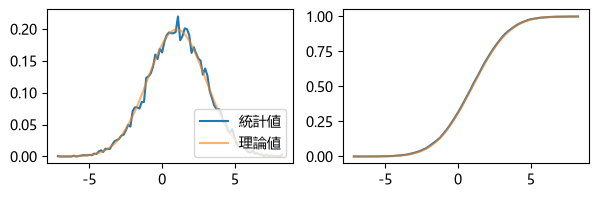

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 2))
ax1.plot(t, pdf, label="統計値")
ax1.plot(t, X.pdf(t), label="理論値", alpha=0.6)
ax1.legend(loc="lower right")
ax2.plot(t, cdf)
ax2.plot(t, X.cdf(t), alpha=0.6);

有些分布除了 `loc` 与 `scale` 之外还需要形状参数。例如伽马分布表示独立随机事件发生 $k$ 次所需的时间，其中 $k$ 就是形状参数。下面计算 $k=1$ 与 $k=2$ 时的期望和方差。

In [9]:
print(stats.gamma.stats(1.0))
print(stats.gamma.stats(2.0))

(np.float64(1.0), np.float64(1.0))
(np.float64(2.0), np.float64(2.0))


尺度参数 $\theta$ 与事件发生的频度有关，用 `scale` 指定。

In [10]:
stats.gamma.stats(2.0, scale=2)

(np.float64(4.0), np.float64(8.0))

伽马分布的期望是 $k \theta$、方差是 $k \theta^2$，不妨确认上面的结果是否符合这两个式子。

有形状参数的分布，在调用 `rvs()` 和 `pdf()` 时同样要传形状参数：下面的代码从 $k=2$、$\theta=2$ 的伽马分布生成 4 个随机数。

In [11]:
x = stats.gamma.rvs(2, scale=2, size=4)
x

array([3.65620127, 2.57801691, 4.68450543, 5.20642448])

用 `pdf()` 算出这 4 个值处的概率密度。

In [12]:
stats.gamma.pdf(x, 2, scale=2)

array([0.14690483, 0.17758918, 0.11255799, 0.0963649 ])

也可以先做出形状参数与尺度参数都固定的随机变量，再调用它的 `pdf()`。

In [13]:
X = stats.gamma(2, scale=2)
X.pdf(x)

array([0.14690483, 0.17758918, 0.11255799, 0.0963649 ])

## 离散概率分布

取值一跳一跳的分布叫离散概率分布：骰子的点数是 1 到 6 的整数，所以是离散分布，而离散分布用概率质量函数(PMF)表示。

`stats` 模块里的离散分布派生自 `rv_discrete` 类，用这个类就可以自己做出分布。例如有一个各面概率不同的偏心骰子，把出现的点数放在数组 `x` 里、对应的概率放在数组 `p` 里。

In [14]:
x = list(range(1, 7))
p = [0.4, 0.2, 0.1, 0.1, 0.1, 0.1]

做出这个骰子对应的随机变量 `dice`，再输出掷 20 次的结果。

In [15]:
dice = stats.rv_discrete(values=(x, p))
dice.rvs(size=20)

array([1, 5, 1, 1, 6, 2, 1, 2, 3, 1, 1, 3, 4, 1, 1, 1, 5, 2, 1, 5])

接下来确认中心极限定理，它说的是：把大量独立的随机变量加起来，其平均值的分布会趋近正态分布。

把这个骰子掷 50 次并求平均，由于每次的点数相互独立，50 次的平均就可以看成「许多独立随机变量的平均」。这里用 `rvs()` 生成形状 `(20000, 50)` 的随机数，再按行求平均。

In [16]:
np.random.seed(42)
samples = dice.rvs(size=(20000, 50))
samples_mean = np.mean(samples, axis=1)

## 核密度估计

骰子的点数是离散的，它的平均也是离散的，画成直方图就会看到很多值挤在同一区间里、高低起伏很厉害。想看光滑的密度时，就用 `gaussian_kde()` 做核密度估计。

下图中直方图抖动得厉害，而核密度估计的曲线已经接近拟合出的正态分布，中心极限定理由此得到了确认。

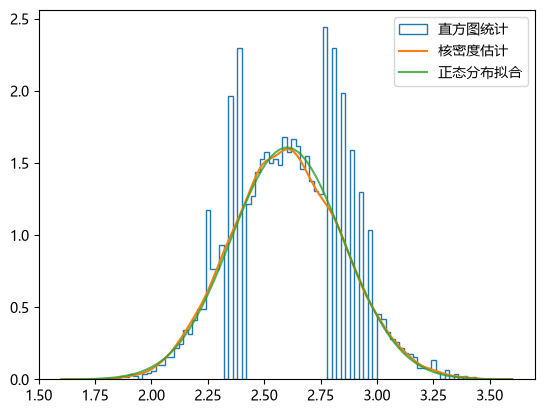

In [17]:
from scipy.stats import gaussian_kde

_, bins, step = plt.hist(
    samples_mean, bins=100, density=True, histtype="step", label="直方图统计"
)
kde = gaussian_kde(samples_mean)
x = np.linspace(bins[0], bins[-1], 100)
plt.plot(x, kde(x), label="核密度估计")
mean, std = stats.norm.fit(samples_mean)
plt.plot(x, stats.norm(mean, std).pdf(x), alpha=0.8, label="正态分布拟合")
plt.legend();

核密度估计是在每个数据点上放一条核函数曲线，再把它们加起来；`gaussian_kde()` 用的核是高斯曲线，而 `bw_method` 决定它的宽度。`bw_method` 可以取下面的值。

* `'scott'` 或 `'silverman'`：由数据个数与维数按公式算出宽度。
* 函数：调用它来计算宽度，参数是 `gaussian_kde` 对象。
* 数值：直接把这个值当作宽度。

下图是不同宽度带来的差别：宽度越大曲线越光滑，宽度小时能看到 3 个点的峰，而把宽度调大之后这些峰就并成了一个。

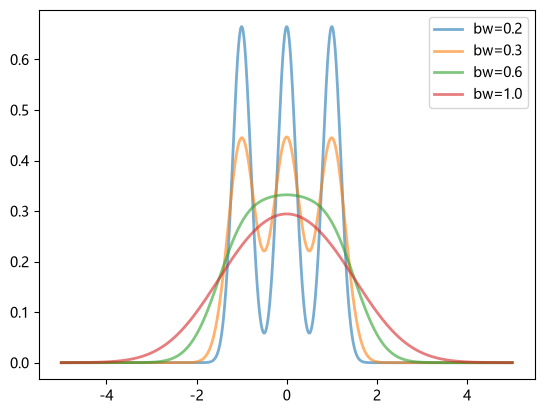

In [18]:
for bw in [0.2, 0.3, 0.6, 1.0]:
    kde = stats.gaussian_kde([-1, 0, 1], bw_method=bw)
    x = np.linspace(-5, 5, 1000)
    y = kde(x)
    plt.plot(x, y, lw=2, label="bw={}".format(bw), alpha=0.6)
plt.legend(loc="best");

## 二项分布、泊松分布、伽马分布

这里用随机数确认二项分布、泊松分布与伽马分布。

二项分布表示把只有两种结果的实验做 $n$ 次、其中成功 $k$ 次的概率。设成功概率为 $p$，概率质量函数如下。

$$f(k;n,p) = \frac{n!}{k!(n-k)!} p^k(1-p)^{n-k}$$

例如计算掷 5 次骰子出现 3 次 6 的概率：一次出现 6 的概率是 $p=1/6$，次数是 $n=5$；`pmf()` 的第 1 个参数是随机变量的取值，之后依次传 $n$ 与 $p$。

In [19]:
stats.binom.pmf(range(6), 5, 1 / 6.0)

array([4.01877572e-01, 4.01877572e-01, 1.60751029e-01, 3.21502058e-02,
       3.21502058e-03, 1.28600823e-04])

6 出现 0 次的概率是 40.2%，出现 1 次也是 40.2%，出现 3 次则是 3.2%。

二项分布在 $n$ 大、$p$ 小的时候，只要乘积 $n p$ 大小合适，成功次数的分布就可以用泊松分布近似。设单位时间内随机事件发生的平均次数为 $\lambda$，泊松分布的式子如下。

$$f(k;\lambda)=\frac{e^{-\lambda}\lambda^k}{k!}$$

把二项分布里的 $n$ 当作单位时间的实验次数，就有 $\lambda = n \cdot p$。下面的代码把 $n=100$ 与 $n=1000$ 的二项分布同 $\lambda=10$ 的泊松分布作比较，可见 $n$ 越大两者越接近。

max err1=0.006755 max err2=0.000630


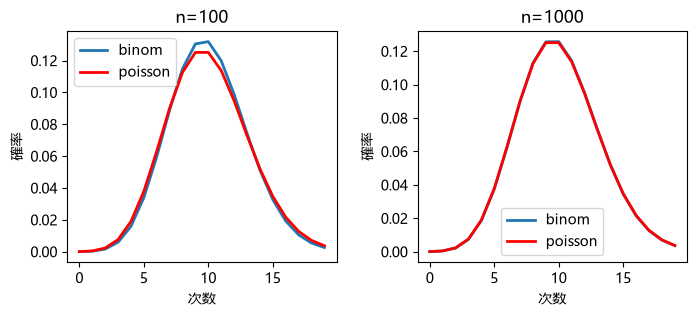

In [20]:
lambda_ = 10.0
x = np.arange(20)

n1, n2 = 100, 1000

y_binom_n1 = stats.binom.pmf(x, n1, lambda_ / n1)
y_binom_n2 = stats.binom.pmf(x, n2, lambda_ / n2)
y_poisson = stats.poisson.pmf(x, lambda_)
print(
    "max err1={:8.6f} max err2={:8.6f}".format(
        np.max(np.abs(y_binom_n1 - y_poisson)), np.max(np.abs(y_binom_n2 - y_poisson))
    )
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3))
ax1.plot(x, y_binom_n1, label="binom", lw=2)
ax1.plot(x, y_poisson, label="poisson", lw=2, color="red")
ax2.plot(x, y_binom_n2, label="binom", lw=2)
ax2.plot(x, y_poisson, label="poisson", lw=2, color="red")
for n, ax in zip((n1, n2), (ax1, ax2)):
    ax.set_xlabel("次数")
    ax.set_ylabel("確率")
    ax.set_title("n={}".format(n))
    ax.legend()
fig.subplots_adjust(wspace=0.3);

泊松分布表示一定时间内事件发生次数的分布，适用于设施的使用次数、机器的故障次数、灾害的发生次数等。

这里用随机数生成泊松分布，再与概率质量函数比较：让每秒平均发生 10 次($\lambda=10$)的事件分别在 1000 秒与 50000 秒内发生，观测时间越长，每秒次数的分布就越接近泊松分布。

time=1000, max_error= 0.020
time=50000, max_error= 0.002


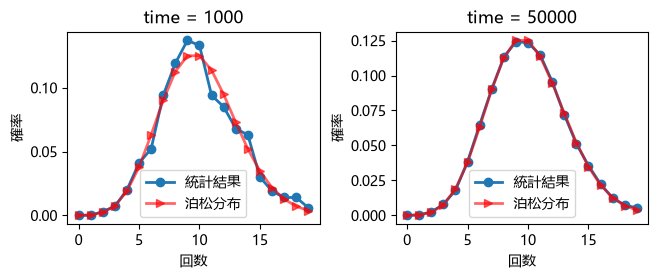

In [21]:
np.random.seed(42)


def sim_poisson(lambda_, time):
    t = np.random.uniform(0, time, size=lambda_ * time)  #❶
    count, time_edges = np.histogram(t, bins=time, range=(0, time))  #❷
    dist, count_edges = np.histogram(count, bins=20, range=(0, 20), density=True)  #❸
    x = count_edges[:-1]
    poisson = stats.poisson.pmf(x, lambda_)
    return x, poisson, dist


lambda_ = 10
times = 1000, 50000
x1, poisson1, dist1 = sim_poisson(lambda_, times[0])
x2, poisson2, dist2 = sim_poisson(lambda_, times[1])
max_error1 = np.max(np.abs(dist1 - poisson1))
max_error2 = np.max(np.abs(dist2 - poisson2))
print("time={}, max_error={:6.3f}".format(times[0], max_error1))
print("time={}, max_error={:6.3f}".format(times[1], max_error2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.5, 2.5))

ax1.plot(x1, dist1, "-o", lw=2, label="統計結果")
ax1.plot(x1, poisson1, "->", lw=2, label="泊松分布", color="red", alpha=0.6)
ax2.plot(x2, dist2, "-o", lw=2, label="統計結果")
ax2.plot(x2, poisson2, "->", lw=2, label="泊松分布", color="red", alpha=0.6)

for ax, time in zip((ax1, ax2), times):
    ax.set_xlabel("回数")
    ax.set_ylabel("確率")
    ax.set_title("time = {}".format(time))
    ax.legend(loc="lower center")

fig.subplots_adjust(wspace=0.3);

❶ 用 `uniform()` 生成从 0 到 `time` 的均匀随机数共 `lambda_*time` 个，作为事件发生的时刻。❷ 用 `histogram()` 数出每秒的事件次数 `count`。❸ 再把这些次数按 0 到 20 的范围统计，`density=True` 时的含义与概率质量函数相同。

也可以换个角度看，看看相邻事件之间的间隔、以及相隔 $k$ 个事件的间隔的分布。事件间隔服从伽马分布，由于间隔是连续的值，所以伽马分布是连续分布。概率密度函数如下，表示等到第 $k$ 个事件所需的时间，其中 $\Gamma(k)$ 是伽马函数，$k$ 为整数时等于 $k!$。

$$f(X;k, \lambda)=\frac{X^{(k-1)}\lambda^{k} e^{(-\lambda X)}}{\Gamma(k)}$$

下面的代码把事件间隔的分布与伽马分布作比较：观测时间 1000 秒、每秒平均 10 次，其中 $k=1$ 是相邻事件的间隔、$k=2$ 是隔一个事件的间隔，两者都服从伽马分布。

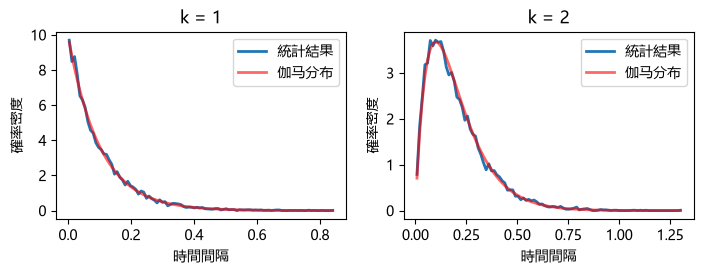

In [22]:
def sim_gamma(lambda_, time, k):
    t = np.random.uniform(0, time, size=lambda_ * time)  #❶
    t.sort()  #❷
    interval = t[k:] - t[:-k]  #❸
    dist, interval_edges = np.histogram(interval, bins=100, density=True)  #❹
    x = (interval_edges[1:] + interval_edges[:-1]) / 2  #❺
    gamma = stats.gamma.pdf(x, k, scale=1.0 / lambda_)  #❺
    return x, gamma, dist


lambda_ = 10.0
time = 1000
ks = 1, 2
x1, gamma1, dist1 = sim_gamma(int(lambda_), time, ks[0])
x2, gamma2, dist2 = sim_gamma(int(lambda_), time, ks[1])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.5, 2.5))

ax1.plot(x1, dist1, lw=2, label="統計結果")
ax1.plot(x1, gamma1, lw=2, label="伽马分布", color="red", alpha=0.6)
ax2.plot(x2, dist2, lw=2, label="統計結果")
ax2.plot(x2, gamma2, lw=2, label="伽马分布", color="red", alpha=0.6)

for ax, k in zip((ax1, ax2), ks):
    ax.set_xlabel("時間間隔")
    ax.set_ylabel("確率密度")
    ax.set_title("k = {}".format(k))
    ax.legend(loc="upper right")

fig.subplots_adjust(0.1, 0.15, 0.95, 0.90, 0.2, 0.1);

❶ 在 1000 秒内按随机时刻发生 10000 个事件，平均每秒 10 次。❷ 为了计算间隔，先把时刻排序。❸ 算出相隔 $k$ 个事件的间隔。❹ 再对这个间隔取直方图，因为 `density=True`，所以可以直接与概率密度比较。❺ 给 `gamma.pdf()` 传入各区间中点，第 2 个参数是 $k$、`scale` 是 $1/\lambda$。

接下来看一个用伽马分布的概率问题：A、B 两路公交车的平均发车间隔分别是 5 分钟和 10 分钟，乘客在车站 S 随便坐哪一路，平均要等多少分钟，假设到站时刻完全随机。

如果到站完全随机，单位时间内到达 S 的车数服从泊松分布，间隔服从 $k=1$ 的伽马分布。先用随机数近似，再用式子确认。

In [23]:
T = 100000
A_count = T // 5
B_count = T // 10

A_time = np.random.uniform(0, T, A_count)  #❶
B_time = np.random.uniform(0, T, B_count)

bus_time = np.concatenate((A_time, B_time))  #❷
bus_time.sort()

N = 200000
passenger_time = np.random.uniform(bus_time[0], bus_time[-1], N)  #❸

idx = np.searchsorted(bus_time, passenger_time)  #❹
np.mean(bus_time[idx] - passenger_time) * 60  #❺

np.float64(202.33887478797047)

仿真的时长是 `T` 分钟，其间 A 到了 `A_count` 辆、B 到了 `B_count` 辆。❶ 用 `uniform()` 生成两路车的到站时刻。❷ 把两个时刻数组合起来排序。

❸ 在首末两班车之间随机生成乘客的到站时刻。❹ 用 `searchsorted()` 找出乘客时刻之后到来的那班车的位置。❺ 它与乘客时刻之差就是等待时间，取平均即可，结果约为 200 秒。

A 与 B 合起来的平均间隔也是 200 秒，所以直觉上等待时间会短于平均间隔，但结果并非如此。

In [24]:
np.mean(np.diff(bus_time)) * 60

np.float64(199.99833251643057)

这就是观测者偏差，因为间隔越长，其间到站的乘客就越多，这与公交车因事故晚点时站台上等的人更多是同一个道理。

下图上方的蓝线是公交到站、红线是乘客到站，蓝线间隔越宽，红线也越密；下图则是横轴为公交间隔、纵轴为该间隔内出现的乘客数，两者成正比。

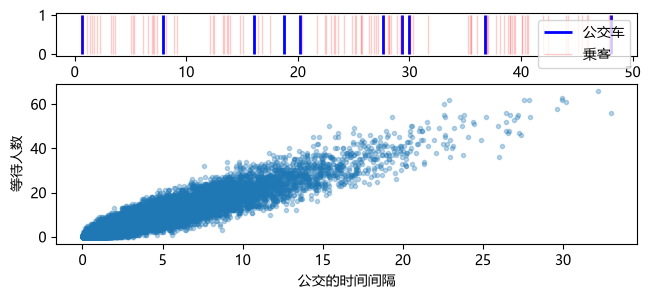

In [25]:
import matplotlib.gridspec as gridspec

plt.figure(figsize=(7.5, 3))

G = gridspec.GridSpec(10, 1)
ax1 = plt.subplot(G[:2, 0])
ax2 = plt.subplot(G[3:, 0])

ax1.vlines(bus_time[:10], 0, 1, lw=2, color="blue", label="公交车")
ptime = np.random.uniform(bus_time[0], bus_time[9], 100)
ax1.vlines(ptime, 0, 1, lw=1, color="red", alpha=0.2, label="乗客")
ax1.legend()
count, bins = np.histogram(passenger_time, bins=bus_time)
ax2.plot(np.diff(bins), count, ".", alpha=0.3, rasterized=True)
ax2.set_xlabel("公交的时间间隔")
ax2.set_ylabel("等待人数");

由此，平均等待时间可以用下面的式子计算。

$$\frac{\int_{0}^{+ \infty }{ \frac{x}{2} x f(x) dx}}{\int_{0}^{+ \infty }{x f(x) dx}}$$

其中 $x$ 是公交的间隔，$f(x)dx$ 是间隔为 $x$ 的概率；由于间隔越长乘客越容易来，$x f(x)dx$ 就与间隔 $x$ 期间有乘客到来的概率成正比。分母则是把它归一化的积分，而分子的 $\frac{x}{2}$ 是那个间隔下的平均等待时间。

公交间隔几乎不会超过 30 分钟，所以积分上限取足够大的值即可，下面的代码就来计算。

In [26]:
from scipy import integrate

t = 10.0 / 3  # 两路公交之间的平均时间间隔
bus_interval = stats.gamma(1, scale=t)
n, _ = integrate.quad(lambda x: 0.5 * x * x * bus_interval.pdf(x), 0, 1000)
d, _ = integrate.quad(lambda x: x * bus_interval.pdf(x), 0, 1000)
n / d * 60

200.0

## 学生 t 分布与 t 检验

从平均值为 $\mu$ 的正态分布中取 $n$ 个值，算出样本平均 $\bar{x}$ 与无偏方差 $s^2$。

$$\begin{align} \bar{x} = \frac{x_1+\cdots+x_n}{n}, \ \ 
s^2 = \frac{1}{n-1}\sum_{i=1}^n (x_i - \bar{x})^2 \end{align}$$

这时 $t = \frac{\bar{x} - \mu}{s/\sqrt{n}}$ 服从自由度为 $df=n-1$ 的 t 分布。$t$ 是把样本平均与总体平均之差除以波动之后归一化的值，可以用来衡量样本与总体的差别。

下面的代码确认 t 分布：❶ 生成形状 `(100000, 10)` 的正态随机数，❷ 按上面的式子计算 $t$，❸ 再把它的分布与 `stats.t` 的概率密度函数比较。由 10 个值算出的 $t$ 应当服从自由度 9 的 t 分布。

max error=0.0068


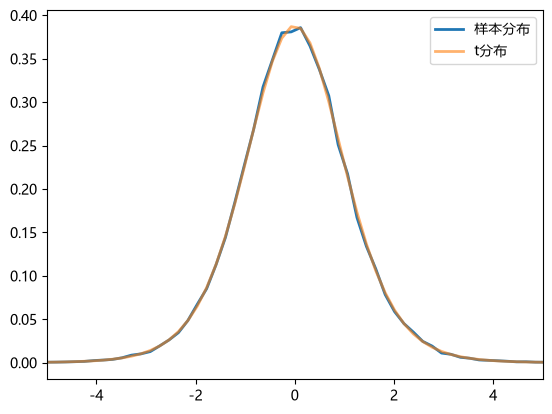

In [27]:
mu = 0.0
n = 10
samples = stats.norm(mu).rvs(size=(100000, n))  #❶
t_samples = (np.mean(samples, axis=1) - mu) / (
    np.std(samples, ddof=1, axis=1) / n**0.5
)  #❷
sample_dist, x = np.histogram(t_samples, bins=100, density=True)  #❸
x = 0.5 * (x[:-1] + x[1:])
t_dist = stats.t(n - 1).pdf(x)
print("max error={:6.4f}".format(np.max(np.abs(sample_dist - t_dist))))

plt.plot(x, sample_dist, lw=2, label="样本分布")
plt.plot(x, t_dist, lw=2, alpha=0.6, label="t分布")
plt.xlim(-5, 5)
plt.legend(loc="best");

下图是自由度 5 与 39 的概率密度函数和生存函数：自由度越大，t 分布越接近正态分布。

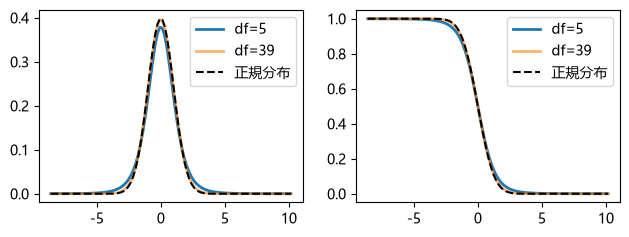

In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.5, 2.5))
ax1.plot(x, stats.t(6 - 1).pdf(x), label="df=5", lw=2)
ax1.plot(x, stats.t(40 - 1).pdf(x), label="df=39", lw=2, alpha=0.6)
ax1.plot(x, stats.norm.pdf(x), "k--", label="正規分布")
ax1.legend()

ax2.plot(x, stats.t(6 - 1).sf(x), label="df=5", lw=2)
ax2.plot(x, stats.t(40 - 1).sf(x), label="df=39", lw=2, alpha=0.6)
ax2.plot(x, stats.norm.sf(x), "k--", label="正規分布")
ax2.legend();

t 分布可以用来检验样本的平均值：这里从平均值为 1 的正态分布中取 30 个值。

In [29]:
n = 30
np.random.seed(42)
s = stats.norm.rvs(loc=1, scale=0.8, size=n)

提出「总体平均为 0.5」这一原假设，用 `ttest_1samp()` 看能否拒绝它。返回值的第 1 个是 $t$ 的值、第 2 个是 $p$ 值，若 $p$ 值小于 0.05 就判断原假设不成立。这个结果说明，总体平均为 0.5 这一假设可以被拒绝。

:::{admonition} 原假设
:class: note
原假设(null hypothesis)是检验中提出的假设之一，多数情况下是我们想证明其为错的假设，或者暂时搁在一边的假设。
:::

In [30]:
t = (np.mean(s) - 0.5) / (np.std(s, ddof=1) / np.sqrt(n))
print(t, stats.ttest_1samp(s, 0.5))

2.658584340882224 TtestResult(statistic=np.float64(2.658584340882224), pvalue=np.float64(0.012637702257091193), df=np.int64(29))


接着检验总体平均是否为 1.0：由于 $p$ 值大于 0.05，不能拒绝原假设。不过这并不表示该假设是对的——即使假设总体平均为 0.9，$p$ 值同样大于 0.05，而且比 1.0 时的 $t$ 更大。

In [31]:
print((np.mean(s) - 1) / (np.std(s, ddof=1) / np.sqrt(n)))
print(stats.ttest_1samp(s, 1))
print(stats.ttest_1samp(s, 0.9))

-1.1450173670383303
TtestResult(statistic=np.float64(-1.1450173670383303), pvalue=np.float64(0.261564146188015), df=np.int64(29))
TtestResult(statistic=np.float64(-0.3842970254542196), pvalue=np.float64(0.7035619103425201), df=np.int64(29))


`ttest_1samp()` 的 $p$ 值就是下图中红色部分的面积，它的含义是这样的：如果总体平均与假设的值相同，那么取 $n$ 个值时，$t$ 的绝对值比样本的 $t$ 更大的概率就是 $p$。$p$ 越小，假设成立的可能性越低；反过来，$p$ 大也只能说明无法拒绝原假设，不能说假设就是对的。

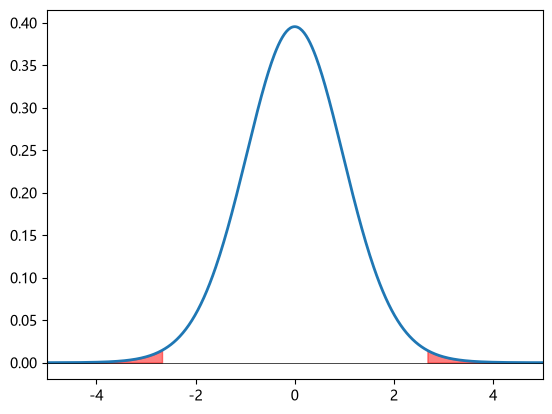

In [32]:
x = np.linspace(-5, 5, 500)
y = stats.t(n - 1).pdf(x)
plt.plot(x, y, lw=2)
t, p = stats.ttest_1samp(s, 0.5)
mask = x > np.abs(t)
plt.fill_between(x[mask], y[mask], color="red", alpha=0.5)
mask = x < -np.abs(t)
plt.fill_between(x[mask], y[mask], color="red", alpha=0.5)
plt.axhline(color="k", lw=0.5)
plt.xlim(-5, 5);

以总体平均 0.5 的检验为例：若总体平均真的是 0.5，那么 $t$ 取到比 2.65858 更大或者比 -2.65858 更小的概率是 0.0126377。既然这个概率很小，就可以判断总体平均不是 0.5。

再用积分确认这个 $p$ 值：左右两块红色面积相等，所以只算一侧再乘 2。

In [33]:
from scipy import integrate

x = np.linspace(-10, 10, 100000)
y = stats.t(n - 1).pdf(x)
mask = x >= np.abs(t)
integrate.trapezoid(y[mask], x[mask]) * 2

np.float64(0.012633433707685974)

用随机数也能确认 $p$ 值：生成 $m$ 组随机数，每组都在「总体平均为 0.5」的假定下算出 $t$，其中绝对值比样本的 $t$ 更大的组所占的比例就是 $p$ 值。

In [34]:
m = 200000
mean = 0.5
r = stats.norm.rvs(loc=mean, scale=0.8, size=(m, n))
ts = (np.mean(s) - mean) / (np.std(s, ddof=1) / np.sqrt(n))
tr = (np.mean(r, axis=1) - mean) / (np.std(r, ddof=1, axis=1) / np.sqrt(n))
np.mean(np.abs(tr) > np.abs(ts))

np.float64(0.012695)

如果 `s1` 与 `s2` 是从正态总体中独立取出的样本，就可以用 `ttest_ind()` 检验两个总体平均是否有差别，其中 `equal_var` 用来指定两个总体的方差是否相同。

下面的例子里，❶ `s1` 与 `s2` 来自方差不同的总体，所以取 `equal_var=False`，由于 $p<0.05$，可以判断两者的总体平均有差别；❷ `s2` 与 `s3` 来自方差相同的总体，所以取 `equal_var=True`，由于 $p$ 值非常大，无法拒绝「总体平均相同」这一原假设。

In [35]:
np.random.seed(42)

s1 = stats.norm.rvs(loc=1, scale=1.0, size=20)
s2 = stats.norm.rvs(loc=1.5, scale=0.5, size=20)
s3 = stats.norm.rvs(loc=1.5, scale=0.5, size=25)

print(stats.ttest_ind(s1, s2, equal_var=False))  #❶
print(stats.ttest_ind(s2, s3, equal_var=True))  #❷

TtestResult(statistic=np.float64(-2.2391470627176755), pvalue=np.float64(0.033250866086743706), df=np.float64(28.072969108063))
TtestResult(statistic=np.float64(-0.5946698521856172), pvalue=np.float64(0.555180587581054), df=np.float64(43.0))


## 卡方分布与卡方检验

卡方分布($\chi ^{2}$)也是统计里常用的分布：$k$ 个独立标准正态变量的平方和服从自由度为 $k$ 的卡方分布，下面用随机数确认。

max error: 0.0031


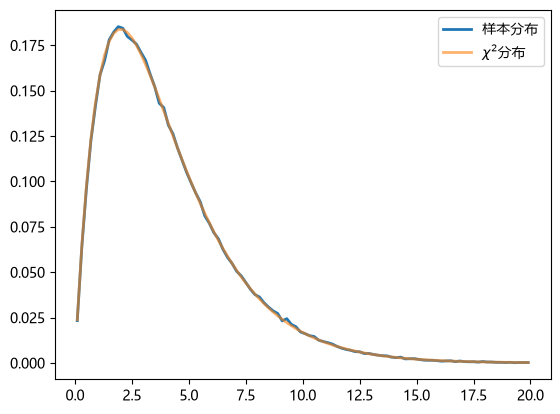

In [36]:
a = np.random.normal(size=(300000, 4))
cs = np.sum(a**2, axis=1)

sample_dist, bins = np.histogram(cs, bins=100, range=(0, 20), density=True)
x = 0.5 * (bins[:-1] + bins[1:])
chi2_dist = stats.chi2.pdf(x, 4)
print("max error: {:6.4f}".format(np.max(np.abs(sample_dist - chi2_dist))))

plt.plot(x, sample_dist, lw=2, label="样本分布")
plt.plot(x, chi2_dist, lw=2, alpha=0.6, label=r"$\chi ^{2}$分布")
plt.legend(loc="best");

卡方分布也适用于下面这样的现象：袋子里装着 5 种颜色的球、每种数量相同，取 $N$ 次并数出各颜色的次数 $O_i$，这时下面的 $\chi^2$ 服从自由度为 4 的卡方分布，其中 $E=N/5$ 是各颜色的期望次数。

$$\chi^2 = \sum_{i=1}^{k}{\frac{(O_i-E)^2}{E}}$$

下面的代码做仿真：❶ 用 `randint()` 生成 0 到 4 的随机数，行代表一次实验、列代表一次取出的 100 个球。❷ 用 `bincount()` 数出各颜色的次数，由于 `bincount()` 不支持多维，所以用 `apply_along_axis()` 逐行调用，并用 `minlength=5` 把结果长度补齐。❸ 按上面的式子算出 $\chi^2$，❹ 再用 `gaussian_kde()` 估计它的分布。

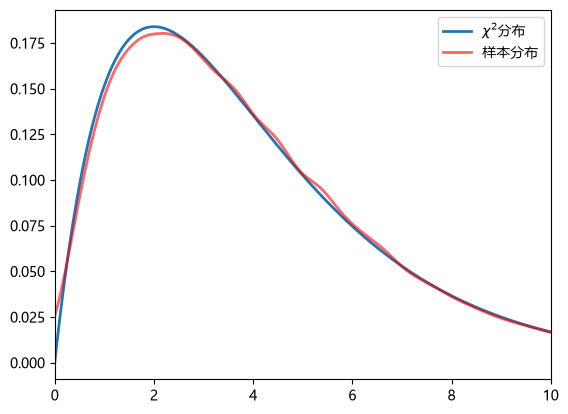

In [37]:
repeat_count = 60000
n, k = 100, 5

np.random.seed(42)
ball_ids = np.random.randint(0, k, size=(repeat_count, n))  #❶
counts = np.apply_along_axis(np.bincount, 1, ball_ids, minlength=k)  #❷
cs2 = np.sum((counts - n / k) ** 2.0 / (n / k), axis=1)  #❸
k = gaussian_kde(cs2)
x = np.linspace(0, 10, 200)
plt.plot(x, stats.chi2.pdf(x, 4), lw=2, label=r"$\chi ^{2}$分布")
plt.plot(x, k(x), lw=2, color="red", alpha=0.6, label="样本分布")
plt.legend(loc="best")
plt.xlim(0, 10);

卡方检验用来判断观测值与理论值之差能否用偶然的波动来解释。

下面的例子用 `probabilities` 指定袋中各颜色球的概率：`choose_balls(probabilities, size)` 从袋中取 `size` 次并返回各颜色的次数。袋子 1 的概率是 0.18、0.24、0.25、0.16、0.17，袋子 2 则是 5 种颜色各占 0.2，取出的结果分别是 `counts1` 与 `counts2`，现在来检验这两个袋子是否均匀。

In [38]:
def choose_balls(probabilities, size):
    s = stats.rv_discrete(values=(range(len(probabilities)), probabilities)).rvs(
        size=size
    )
    counts = np.bincount(s)
    return counts


np.random.seed(42)
counts1 = choose_balls([0.18, 0.24, 0.25, 0.16, 0.17], 400)
counts2 = choose_balls([0.2] * 5, 400)

%C counts1; counts2

      counts1               counts2       
--------------------  --------------------
[80, 93, 97, 64, 66]  [89, 76, 79, 71, 85]


用 `chisquare()` 做卡方检验，参数是各颜色的次数；不传目标概率时，检验的就是分布是否均匀。原假设是「样本服从目标概率」。

袋子 1 的 $p$ 值是 0.02：如果分布均匀，出现这种结果的概率只有 2%，因此可以拒绝原假设，袋子 1 不能说成均匀的。袋子 2 的 $p$ 值是 0.64，无法拒绝原假设——不过这也并不等于证明了袋子 2 是均匀的。

In [39]:
chi1, p1 = stats.chisquare(counts1)
chi2, p2 = stats.chisquare(counts2)

print("chi1 = {:7.4f} p1 = {:6.4f}".format(chi1, p1))
print("chi1 = {:7.4f} p1 = {:6.4f}".format(chi2, p2))

chi1 = 11.3750 p1 = 0.0227
chi1 =  2.5500 p1 = 0.6357


卡方检验用卡方分布的面积来计算 $p$ 值：下图是自由度为 4 的卡方分布，标出了 $\chi_1^2$ 与 $\chi_2^2$ 的位置，其中 $p_1$ 是 $\chi_1^2$ 右侧的面积、$p_2$ 是 $\chi_2^2$ 右侧的面积。

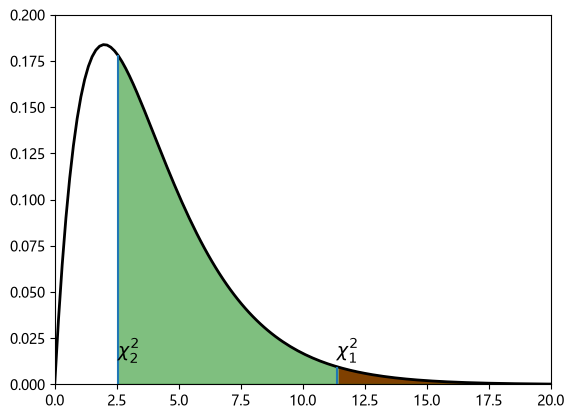

In [40]:
x = np.linspace(0, 30, 200)
CHI2 = stats.chi2(4)
plt.plot(x, CHI2.pdf(x), "k", lw=2)
plt.vlines(chi1, 0, CHI2.pdf(chi1))
plt.vlines(chi2, 0, CHI2.pdf(chi2))
plt.fill_between(x[x > chi1], 0, CHI2.pdf(x[x > chi1]), color="red", alpha=1.0)
plt.fill_between(x[x > chi2], 0, CHI2.pdf(x[x > chi2]), color="green", alpha=0.5)
plt.text(chi1, 0.015, r"$\chi^2_1$", fontsize=14)
plt.text(chi2, 0.015, r"$\chi^2_2$", fontsize=14)
plt.ylim(0, 0.2)
plt.xlim(0, 20);

卡方检验也能用在二维数据上：把样本按两个属性分类做成的表叫列联表，下面是性别与惯用手的列联表，现在要由这个结果检验性别与惯用手之间是否有关联。

| 　 | 右手 | 左手 |
| :-- | :-- | :-- |
| 男性 | 43 | 9 |
| 女性 | 44 | 4 |

用 `chi2_contingency()` 检验，原假设是「性别与惯用手没有关联」，也就是男女左右手的概率相同。$p$ 值是 0.3，因此无法拒绝原假设——从这份数据不能说男女的惯用手存在差别。

In [41]:
table = [[43, 9], [44, 4]]
chi2, p, dof, expected = stats.chi2_contingency(table)
%C chi2; p

             chi2                             p              
------------------------------  -----------------------------
np.float64(1.0724852071005921)  np.float64(0.300384770390566)


对 2×2 这样的小列联表，可以用 `fisher_exact()` 计算精确的 $p$ 值。

In [42]:
stats.fisher_exact(table)

SignificanceResult(statistic=np.float64(0.43434343434343436), pvalue=np.float64(0.2391569568222429))

## 小结

* 随机变量是 `stats` 里的对象，带有 `pdf`、`cdf`、`rvs`、`stats`、`fit` 等方法。
* 把随机数的直方图与概率密度函数比较，就能确认分布的公式。
* 离散分布可以用 `rv_discrete` 自己做；中心极限定理说的是平均值的分布趋近正态分布。
* 二项分布在 $n$ 大、$p$ 小时可用泊松分布近似，而事件的间隔服从伽马分布。
* t 检验用来比较样本的平均；$p$ 值小就能拒绝原假设，但拒绝不了并不等于证明了假设。
* 卡方检验用来查频数的偏差与列联表的关联，2×2 的表还可以用 `fisher_exact()`。